# EDA: BugsInPy and the Stack Overflow corpus

In [1]:
import ast
import json
import re
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent

TOKEN = re.compile(r"[A-Za-z_][A-Za-z0-9_]+")  # same as scripts/baseline/run_baseline.py
def tokens(text):
    return [t.lower() for t in TOKEN.findall(text or "")]

def load_jsonl(path):
    return pd.read_json(path, lines=True, dtype={"bug_id": str, "post_id": str})

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
SPLIT_COLORS = {"train": "#4C72B0", "validation": "#DD8452", "test": "#55A868"}

## 1. BugsInPy

In [2]:
bugs = load_jsonl(ROOT / "data/processed/bugs.jsonl")

splits = json.loads((ROOT / "splits/projects.json").read_text())
project_split = {p: s for s in ("train", "validation", "test") for p in splits[s]}
bugs["split"] = bugs["project"].map(project_split)

def bug_info(row):
    path = ROOT / "data/raw/BugsInPy/projects" / row.project / "bugs" / row.bug_id / "bug.info"
    for line in path.read_text().splitlines():
        if line.startswith("python_version="):
            return line.partition("=")[2].strip().strip('"')
bugs["python_version"] = bugs.apply(bug_info, axis=1)
bugs["py_minor"] = bugs["python_version"].str.extract(r"^(\d+\.\d+)")[0]

bugs["n_test_files"] = bugs["test_files"].str.len()
bugs["n_src_files"] = bugs["changes"].apply(len)
bugs["n_src_lines"] = bugs["changes"].apply(lambda cs: sum(len(c["lines"]) for c in cs))
bugs["n_test_changed_files"] = bugs["test_changes"].apply(len)

print(f"{len(bugs)} bugs, {bugs.project.nunique()} projects")
print("unassigned to a split:", bugs.split.isna().sum())
bugs.groupby("split").agg(projects=("project", "nunique"), bugs=("bug_id", "size")).reindex(["train", "validation", "test"])

501 bugs, 17 projects
unassigned to a split: 0


,projects,bugs
split,,
train,5,309
validation,4,97
test,8,95


### Bugs per project

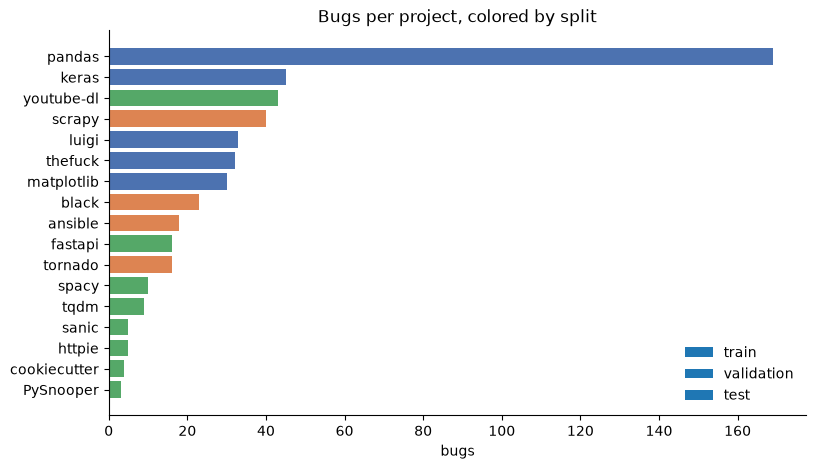

In [3]:
per_project = bugs.groupby(["project", "split"]).size().reset_index(name="bugs").sort_values("bugs")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(per_project.project, per_project.bugs, color=per_project.split.map(SPLIT_COLORS))
for s, c in SPLIT_COLORS.items():
    ax.barh([], [], color=c, label=s)
ax.legend(frameon=False)
ax.set_xlabel("bugs")
ax.set_title("Bugs per project, colored by split")
plt.show()

### Python versions

In [4]:
pd.crosstab(bugs.py_minor, bugs.split)[["train", "validation", "test"]]

split,train,validation,test
py_minor,,,
3.6,0,18,13
3.7,77,16,57
3.8,232,63,25


### Fix size (ground truth)

In [5]:
bugs[["n_src_files", "n_src_lines", "n_test_files", "n_test_changed_files"]].describe().round(2)

,n_src_files,n_src_lines,n_test_files,n_test_changed_files
count,501.00,501.00,501.00,501.0
mean,1.20,14.38,1.07,0.1
std,0.63,119.68,0.26,0.4
min,0.00,0.00,1.00,0.0
25%,1.00,1.00,1.00,0.0
50%,1.00,2.00,1.00,0.0
75%,1.00,5.00,1.00,0.0
max,8.00,1582.00,3.00,4.0


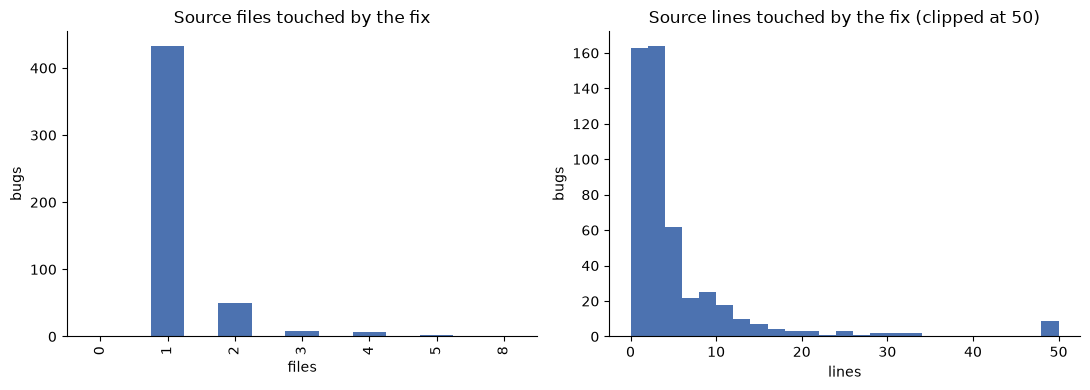

bugs with no source change (test-only fix, unscorable): 1
single-file fixes: 0.864
fixes touching <= 5 lines: 0.776


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bugs.n_src_files.value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set(title="Source files touched by the fix", xlabel="files", ylabel="bugs")
clipped = bugs.n_src_lines.clip(upper=50)
axes[1].hist(clipped, bins=range(0, 52, 2), color="#4C72B0")
axes[1].set(title="Source lines touched by the fix (clipped at 50)", xlabel="lines", ylabel="bugs")
plt.tight_layout(); plt.show()

print("bugs with no source change (test-only fix, unscorable):", (bugs.n_src_lines == 0).sum())
print("single-file fixes:", (bugs.n_src_files == 1).mean().round(3))
print("fixes touching <= 5 lines:", (bugs.n_src_lines <= 5).mean().round(3))

In [7]:
bugs.groupby("project")[["n_src_files", "n_src_lines"]].median().join(
    bugs.groupby("project").size().rename("bugs")).sort_values("bugs", ascending=False)

,n_src_files,n_src_lines,bugs
project,,,
pandas,1.0,2.0,169
keras,1.0,2.0,45
youtube-dl,1.0,2.0,43
scrapy,1.0,2.0,40
luigi,1.0,1.0,33
thefuck,1.0,2.0,32
matplotlib,1.0,2.0,30
black,1.0,3.0,23
ansible,1.0,3.0,18


### Where the fixes land

In [8]:
files = bugs.explode("changes").dropna(subset=["changes"])
files["file"] = files.changes.str["file"]
files["top_dir"] = files.file.str.split("/").str[:2].str.join("/")
files.groupby("project").top_dir.agg(lambda s: s.value_counts().head(3).to_dict())

project
PySnooper       {'pysnooper/tracer.py': 2, 'pysnooper/pycompat...
ansible                                       {'lib/ansible': 19}
black           {'black.py': 21, 'blib2to3/pgen2': 4, 'blib2to...
cookiecutter    {'cookiecutter/generate.py': 2, 'cookiecutter/...
fastapi         {'fastapi/routing.py': 7, 'fastapi/openapi': 3...
httpie          {'httpie/downloads.py': 1, 'httpie/client.py':...
keras           {'keras/engine': 13, 'keras/backend': 11, 'ker...
luigi           {'luigi/scheduler.py': 11, 'luigi/contrib': 8,...
matplotlib      {'lib/matplotlib': 34, 'examples/userdemo': 2,...
pandas          {'pandas/core': 192, 'pandas/io': 10, 'pandas/...
sanic           {'sanic/app.py': 2, 'sanic/server.py': 1, 'san...
scrapy          {'scrapy/utils': 10, 'scrapy/http': 7, 'scrapy...
spacy           {'spacy/errors.py': 4, 'spacy/util.py': 2, 'sp...
thefuck         {'thefuck/rules': 22, 'thefuck/shells': 8, 'th...
tornado         {'tornado/ioloop.py': 4, 'tornado/websocket.py...
tq

### Reproduction runs

Only the bugs that `run_bugs.py` has run so far have a file under `runs/`. A bug is usable
for the full baseline only when it is `reproduced` (fails buggy, passes fixed).

In [9]:
runs = []
for path in sorted((ROOT / "runs").glob("*/*.json")):
    r = json.loads(path.read_text())
    cmds = r["versions"]["buggy"]["commands"]
    tb = "\n".join(c.get("traceback") or "" for c in cmds)
    exc = next((c.get("exception") for c in cmds if c.get("exception")), None)
    runs.append({
        "project": r["project"], "bug_id": str(r["bug_id"]), "reproduced": r["reproduced"],
        "buggy_outcome": r["versions"]["buggy"]["outcome"],
        "fixed_outcome": r["versions"].get("fixed", {}).get("outcome"),
        "seconds": r.get("seconds"),
        "exception": exc, "traceback": tb,
    })
runs = pd.DataFrame(runs)
runs["exc_type"] = runs.exception.str.extract(r"^([A-Za-z_][\w.]*)")[0].replace("assert", "AssertionError")  # pytest prints bare "assert ..."
runs["tb_tokens"] = runs.traceback.apply(lambda t: len(tokens(t)))
runs["tb_frames"] = runs.traceback.str.count(r'File "')

cov = bugs.merge(runs[["project", "bug_id", "reproduced"]], on=["project", "bug_id"], how="left")
cov["status"] = cov.reproduced.map({True: "reproduced", False: "not reproduced"}).fillna("not run")
pd.crosstab(cov.project, cov.status).loc[lambda d: d.get("not run", 0) < d.sum(axis=1)]

status,not reproduced,not run,reproduced
project,,,
PySnooper,1,0,2
ansible,4,0,14
black,1,0,22
pandas,0,168,1
scrapy,1,0,39
tornado,0,0,16


In [10]:
print(pd.crosstab(cov.split, cov.status))
runs.loc[~runs.reproduced, ["project", "bug_id", "buggy_outcome", "fixed_outcome", "exception"]]

status      not reproduced  not run  reproduced
split                                          
test                     1       92           2
train                    0      308           1
validation               6        0          91


,project,bug_id,buggy_outcome,fixed_outcome,exception
0,PySnooper,1,passed,passed,NaN
6,ansible,12,error,error,KeyError: 'getpwuid(): uid not found: 1000'
12,ansible,18,failed,failed,AssertionError: assert 'your description' == '...
17,ansible,6,error,error,KeyError: 'getpwuid(): uid not found: 1000'
19,ansible,8,error,error,KeyError: 'getpwuid(): uid not found: 1000'
34,black,21,passed,passed,NaN
47,scrapy,11,passed,passed,NaN


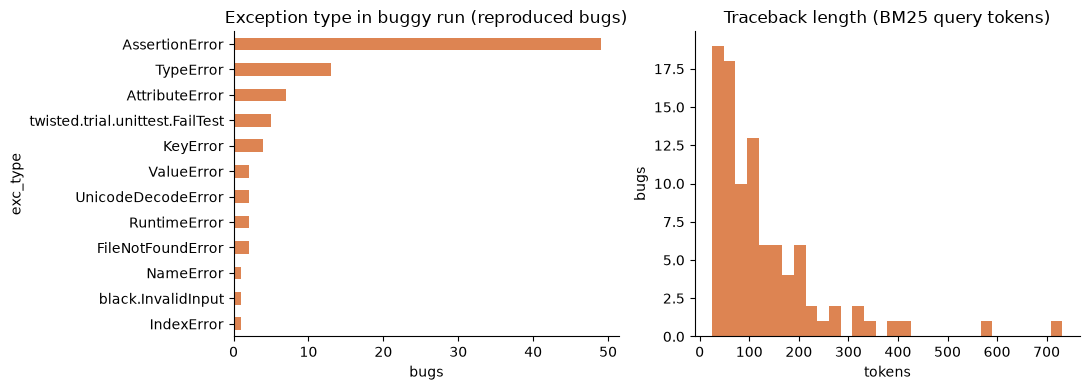

,tb_tokens,tb_frames,seconds
count,94.0,94.0,89.0
mean,128.1,3.8,159.3
std,114.4,4.0,95.6
min,25.0,0.0,8.0
25%,55.2,1.0,66.0
50%,93.5,3.0,187.0
75%,156.2,5.0,253.0
max,732.0,17.0,289.0


In [11]:
rep = runs[runs.reproduced]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rep.exc_type.value_counts().head(12).sort_values().plot.barh(ax=axes[0], color="#DD8452")
axes[0].set(title="Exception type in buggy run (reproduced bugs)", xlabel="bugs")
axes[1].hist(rep.tb_tokens, bins=30, color="#DD8452")
axes[1].set(title="Traceback length (BM25 query tokens)", xlabel="tokens", ylabel="bugs")
plt.tight_layout(); plt.show()
rep[["tb_tokens", "tb_frames", "seconds"]].describe().round(1)

`AssertionError` dominating matters for retrieval: an assertion traceback names the test,
not the faulty library code, so the query carries little about the bug itself.

## 2. Stack Overflow corpus (StaQC `sca_python`)

In [12]:
corpus = load_jsonl(ROOT / "data/processed/corpus.jsonl")
corpus["title"] = corpus.text.str.split("\n", n=1).str[0]
corpus["code"] = corpus.text.str.split("\n", n=1).str[1].fillna("")
corpus["n_chars"] = corpus.text.str.len()
corpus["n_tokens"] = corpus.text.apply(lambda t: len(tokens(t)))
corpus["code_lines"] = corpus.code.str.count("\n") + (corpus.code != "")

print(f"{len(corpus)} rows")
print("duplicate post_id:", corpus.post_id.duplicated().sum(),
      f"({corpus.post_id.nunique()} unique questions)")
print("duplicate text:", corpus.text.duplicated().sum())
print("empty code:", (corpus.code.str.strip() == "").sum())
corpus[["n_chars", "n_tokens", "code_lines"]].describe(percentiles=[.5, .9, .99]).round(1)

85294 rows
duplicate post_id: 0 (85294 unique questions)
duplicate text: 0
empty code: 0


,n_chars,n_tokens,code_lines
count,85294.0,85294.0,85294.0
mean,448.9,49.2,12.8
std,611.9,61.1,17.5
min,23.0,1.0,1.0
50%,280.0,32.0,8.0
90%,919.0,98.0,29.0
99%,2770.1,281.0,81.0
max,25342.0,2553.0,567.0


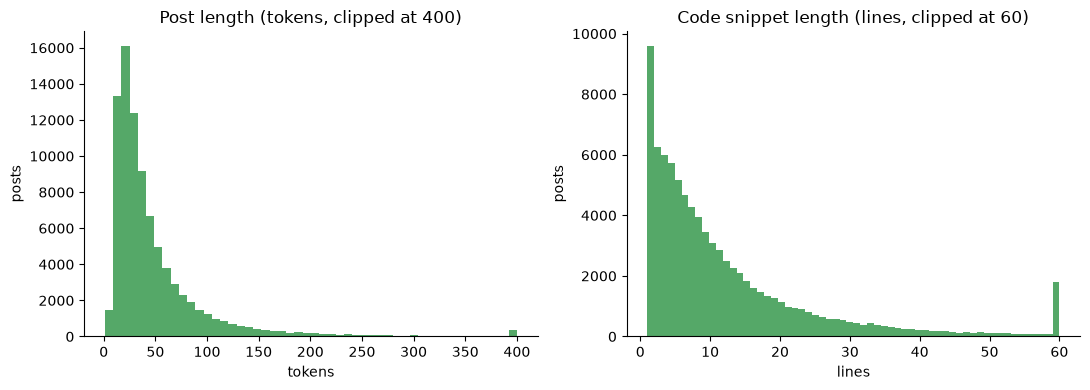

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(corpus.n_tokens.clip(upper=400), bins=50, color="#55A868")
axes[0].set(title="Post length (tokens, clipped at 400)", xlabel="tokens", ylabel="posts")
axes[1].hist(corpus.code_lines.clip(upper=60), bins=60, color="#55A868")
axes[1].set(title="Code snippet length (lines, clipped at 60)", xlabel="lines", ylabel="posts")
plt.tight_layout(); plt.show()

In [14]:
def parse_kind(code):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", SyntaxWarning)  # invalid escapes in old snippets
            ast.parse(code)
        return "python3"
    except (SyntaxError, ValueError):
        pass
    if re.search(r"^\s*print\s+[^\s(=]", code, re.M) or re.search(r"except\s+\w+\s*,\s*\w+\s*:", code):
        return "python2"
    if re.search(r"^\s*(>>>|\$ |In \[\d+\])", code, re.M):
        return "console session"
    return "other / fragment"

corpus["kind"] = corpus.code.apply(parse_kind)
corpus.kind.value_counts(normalize=True).round(3)

kind
python3             0.548
other / fragment    0.159
python2             0.147
console session     0.145
Name: proportion, dtype: float64

In [15]:
for kind in ["other / fragment", "python2"]:
    print(f"--- {kind} ---")
    for t in corpus[corpus.kind == kind].sample(3, random_state=0).text:
        print(t[:300], "\n")

--- other / fragment ---
How to resolve this RDBMS Kind Join functionality in Pandas Dataframe?
df['Pre_Task_ID'] = df[['Pre_Task']].merge(df[['SubTask', 'SubTask_ID']],
                                             right_on='SubTask', left_on='Pre_Task', how='left')['SubTask_ID'].values

                Task1   SubTask SubT 

Recompose a table from an SQL with row and colum ID in Python
df = pd.DataFrame({ 'rowname':[1,1,2,2], 'colname':[1,2,1,2], 'values':['a11','a12','a21','a22'] })

df
   colname  rowname values
0        1        1    a11
1        2        1    a12
2        1        2    a21
3        2        2    a22 

Show 3 fields input in one single field
def _combine(self, cr, uid, ids, field_name, args, context=None):
    values = {}
    for id in ids:
        rec = self.browse(cr, uid, [id], context=context)[0]
        values[id] = {}
        values[id] = '%s %s %s' % (rec.field1, rec.field2, rec.field3)
    

--- python2 ---
executing specific statement at a given rate in py

### What the posts are about

In [16]:
imports = Counter()
for code_text in corpus.code:
    for m in re.finditer(r"^\s*(?:from|import)\s+([A-Za-z_]\w*)", code_text, re.M):
        imports[m.group(1)] += 1
pd.Series(dict(imports.most_common(25)), name="posts importing").to_frame()

,posts importing
matplotlib,3560
numpy,3449
os,2153
sys,2120
re,1441
django,1401
time,1277
pandas,1022
itertools,974
datetime,938


In [17]:
# how much of the corpus mentions each BugsInPy project by name
lower = corpus.text.str.lower()
mentions = {p: lower.str.contains(rf"\b{re.escape(p.lower())}\b", regex=True).sum()
            for p in sorted(bugs.project.unique())}
m = pd.DataFrame({"posts": mentions}).assign(split=lambda d: d.index.map(project_split))
m.sort_values("posts", ascending=False)

,posts,split
pandas,4000,train
matplotlib,3496,train
black,531,validation
scrapy,508,validation
tornado,213,validation
ansible,13,validation
youtube-dl,12,test
keras,10,train
tqdm,5,test
luigi,4,train


## 3. Query vs corpus vocabulary

In [18]:
corpus_df = Counter()
for t in corpus.text:
    corpus_df.update(set(tokens(t)))
N = len(corpus)

def overlap(text):
    toks = set(tokens(text))
    return len([t for t in toks if t in corpus_df]) / len(toks) if toks else float("nan")

rep = rep.assign(vocab_overlap=rep.traceback.apply(overlap))
print("share of a traceback's distinct tokens that appear anywhere in the corpus:")
print(rep.vocab_overlap.describe().round(3))

share of a traceback's distinct tokens that appear anywhere in the corpus:
count    94.000
mean      0.840
std       0.051
min       0.681
25%       0.813
50%       0.850
75%       0.873
max       0.938
Name: vocab_overlap, dtype: float64


In [19]:
# exception types: how often each shows up in tracebacks vs in the corpus
exc_df = rep.exc_type.str.split(".").str[-1].value_counts().head(12).rename("tracebacks").to_frame()
exc_df["corpus_posts"] = [corpus_df.get(e.lower(), 0) for e in exc_df.index]
exc_df["corpus_share"] = (exc_df.corpus_posts / N).round(4)
exc_df

,tracebacks,corpus_posts,corpus_share
exc_type,,,
AssertionError,49,40,0.0005
TypeError,13,305,0.0036
AttributeError,7,270,0.0032
FailTest,5,0,0.0000
KeyError,4,232,0.0027
ValueError,2,654,0.0077
FileNotFoundError,2,9,0.0001
UnicodeDecodeError,2,17,0.0002
RuntimeError,2,64,0.0008


In [20]:
# tokens frequent in tracebacks that the corpus never contains (mostly project-internal names)
tb_df = Counter()
for t in rep.traceback:
    tb_df.update(set(tokens(t)))
missing = [(t, c) for t, c in tb_df.most_common() if t not in corpus_df][:25]
pd.DataFrame(missing, columns=["token", "tracebacks"])

,token,tracebacks
0,blacktestcase,22
1,test_black,22
2,newkeywargs,16
3,orig_method,11
4,assertformatequal,10
5,maybedeferred,8
6,runwithwarningssuppressed,7
7,failtest,5
8,post_coroutine,5
9,future_cell,5
